Loading MNIST dataset...
Building Generator...
Building Discriminator...
Starting GAN training...
Epoch 1/3 completed | Generator Loss: 0.5373 | Discriminator Loss: 0.5316
Epoch 2/3 completed | Generator Loss: 0.9126 | Discriminator Loss: 0.4012
Epoch 3/3 completed | Generator Loss: 0.6251 | Discriminator Loss: 0.4372
Generating sample images...


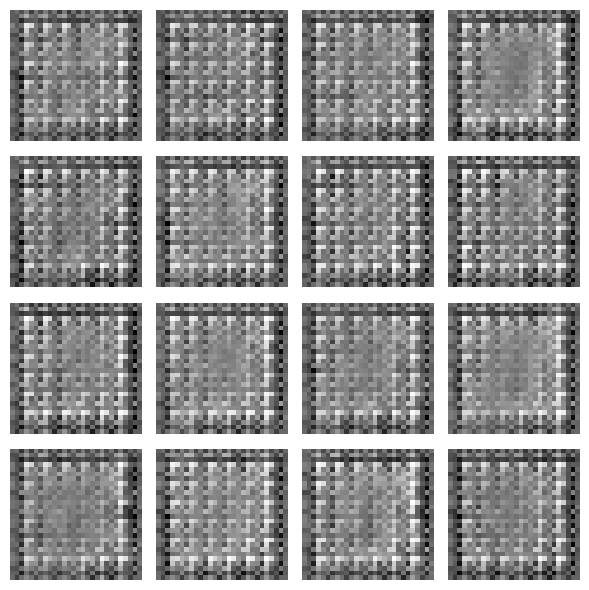

GAN experiment completed!


In [5]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("Loading MNIST dataset...")
(x_train, _), _ = tf.keras.datasets.mnist.load_data()

x_train = x_train[:5000]
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train.reshape(-1, 28, 28, 1)

print("Building Generator...")
generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(7 * 7 * 128),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(64, 4, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(
        1, 4, strides=2, padding="same", activation="tanh"
    )
])

print("Building Discriminator...")
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 4, strides=2, padding="same"),
    layers.LeakyReLU(),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
])

loss_fn = tf.keras.losses.BinaryCrossentropy()

g_optimizer = tf.keras.optimizers.Adam(0.0002)
d_optimizer = tf.keras.optimizers.Adam(0.0002)

@tf.function
def train_step(real_images):
    noise = tf.random.normal((tf.shape(real_images)[0], 100))

    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = loss_fn(tf.ones_like(fake_output), fake_output)
        d_loss = (
            loss_fn(tf.ones_like(real_output), real_output)
            + loss_fn(tf.zeros_like(fake_output), fake_output)
        ) / 2

    g_gradients = g_tape.gradient(
        g_loss, generator.trainable_variables
    )
    d_gradients = d_tape.gradient(
        d_loss, discriminator.trainable_variables
    )

    g_optimizer.apply_gradients(
        zip(g_gradients, generator.trainable_variables)
    )
    d_optimizer.apply_gradients(
        zip(d_gradients, discriminator.trainable_variables)
    )

    return g_loss, d_loss

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(5000).batch(128)

print("Starting GAN training...")
for epoch in range(3):
    g_total = 0
    d_total = 0
    batches = 0

    for images in dataset:
        g_loss, d_loss = train_step(images)
        g_total += float(g_loss)
        d_total += float(d_loss)
        batches += 1

    print(
        f"Epoch {epoch + 1}/3 completed | "
        f"Generator Loss: {g_total / batches:.4f} | "
        f"Discriminator Loss: {d_total / batches:.4f}"
    )

print("Generating sample images...")
noise = tf.random.normal((16, 100))
generated = generator(noise, training=False)

plt.figure(figsize=(6, 6))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated[i, :, :, 0], cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("GAN experiment completed!")